# Customer Segmentation Using K-Means and Hierarchical Clustering

DWM Mini Project


## 1. Import libraries

In [ ]:
import os
import zipfile
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)

print("Libraries imported.")

Libraries imported.


## 2. Download dataset

In [ ]:
data_url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
zip_path = "/content/online_retail.zip" if os.path.exists("/content") else "online_retail.zip"

urllib.request.urlretrieve(data_url, zip_path)

extract_folder = Path("online_retail_data")
extract_folder.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall(extract_folder)

excel_files = list(extract_folder.rglob("*.xlsx"))
if not excel_files:
    raise FileNotFoundError("The Excel dataset was not found in the downloaded ZIP file.")

data_path = excel_files[0]
print("Dataset downloaded and extracted.")
print("File:", data_path)

Dataset downloaded and extracted.
File: online_retail_data/Online Retail.xlsx


## 3. Load dataset

In [ ]:
df_raw = pd.read_excel(data_path)

print("Number of rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

display(df_raw.head())

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 4. Check data

In [ ]:
print("Missing values in each column:")
display(df_raw.isnull().sum())

print("Duplicate rows:", df_raw.duplicated().sum())
display(df_raw.describe(include="all").T)

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


Duplicate rows: 5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Clean data

In [ ]:
df = df_raw.copy()
df.columns = df.columns.str.strip()

df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

rows_before = len(df)

df = df.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"])
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["CustomerID"] = df["CustomerID"].astype("int64").astype(str)
df["Sales"] = df["Quantity"] * df["UnitPrice"]

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Rows removed:", rows_before - len(df))
print("Number of customers:", df["CustomerID"].nunique())

display(df.head())

Rows before cleaning: 541909
Rows after cleaning: 397884
Rows removed: 144025
Number of customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## 6. Explore sales

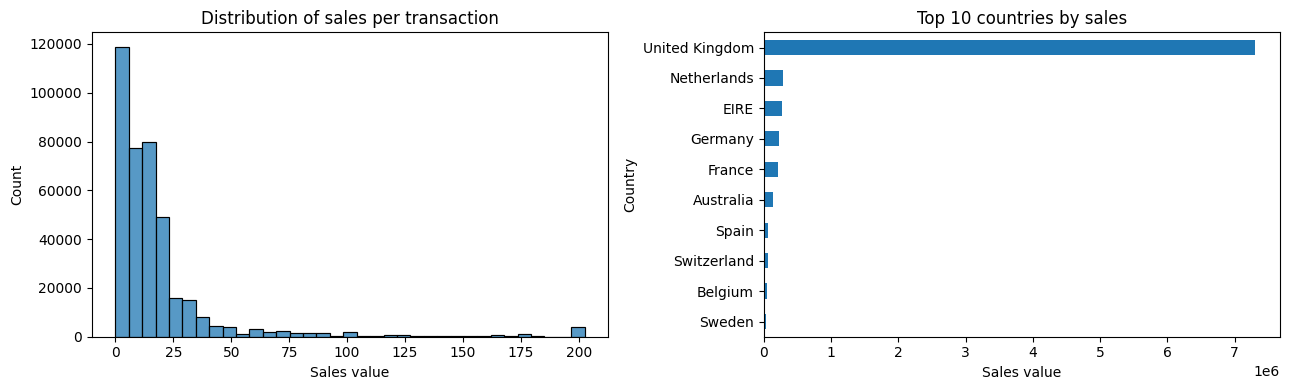

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["Sales"].clip(upper=df["Sales"].quantile(0.99)), bins=35, ax=axes[0])
axes[0].set_title("Distribution of sales per transaction")
axes[0].set_xlabel("Sales value")

country_sales = df.groupby("Country")["Sales"].sum().nlargest(10).sort_values()
country_sales.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 countries by sales")
axes[1].set_xlabel("Sales value")

plt.tight_layout()
plt.show()

## 7. Create RFM values

- **Recency:** Days since last purchase
- **Frequency:** Number of invoices
- **Monetary:** Total amount spent

In [ ]:
snapshot_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (snapshot_date - dates.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna()
rfm = rfm[(rfm["Recency"] >= 0) & (rfm["Frequency"] > 0) & (rfm["Monetary"] > 0)].copy()

print("Reference date:", snapshot_date.date())
print("Customers used for clustering:", len(rfm))
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Reference date: 2011-12-10
Customers used for clustering: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,93.06,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.75,5.00,1661.74
max,374.00,209.00,280206.02


## 8. RFM distributions

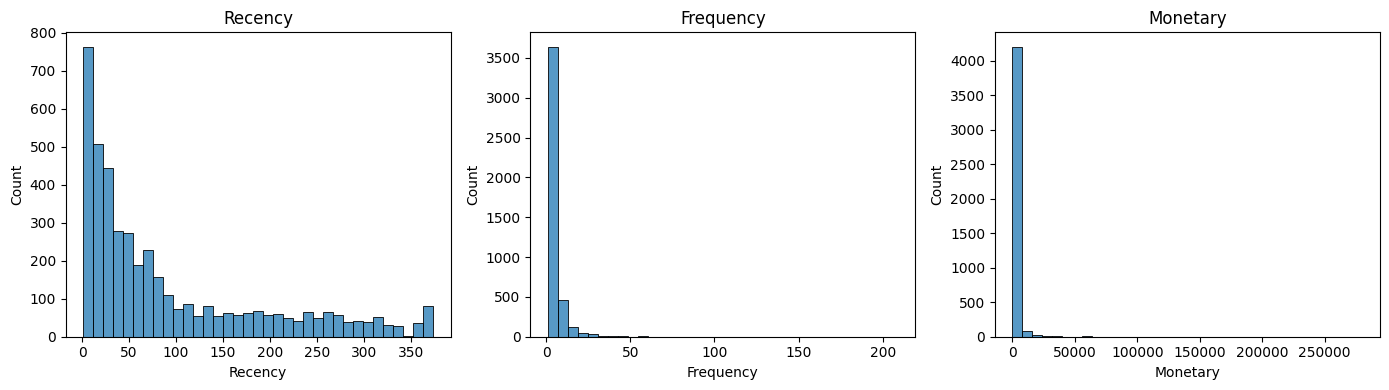

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, column in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[column], bins=35, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

## 9. Prepare data

In [ ]:
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]
rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Features used:", list(rfm_features.columns))
print("Shape of prepared data:", X_scaled.shape)

Features used: ['Recency', 'Frequency', 'Monetary']
Shape of prepared data: (4338, 3)


## 10. Choose number of clusters

,K,Inertia,Silhouette Score
0,2,6474.1464,0.4326
1,3,4856.5855,0.3364
2,4,3924.4597,0.3355
3,5,3268.2119,0.3182
4,6,2840.1514,0.3156
5,7,2533.0244,0.3101
6,8,2325.5230,0.3020


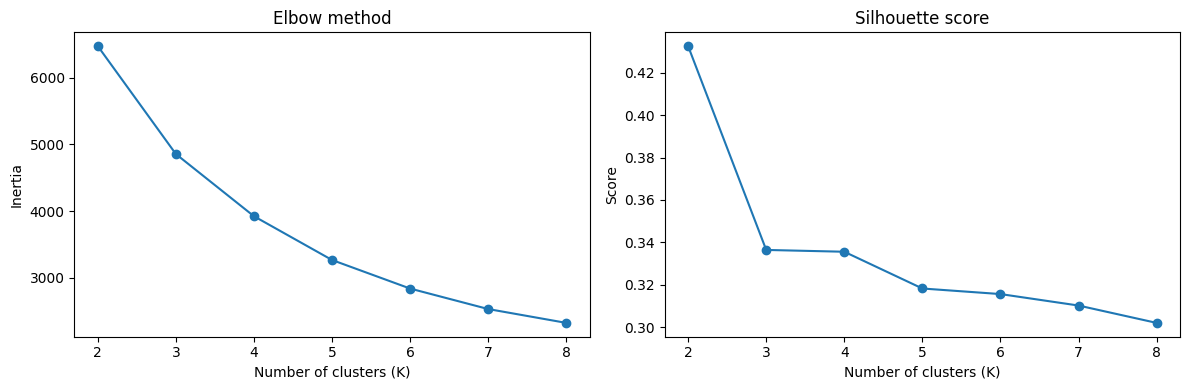

K with the highest silhouette score: 2


In [ ]:
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(evaluation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(evaluation["K"], evaluation["Inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(evaluation["K"], evaluation["Silhouette Score"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

best_k = int(evaluation.loc[evaluation["Silhouette Score"].idxmax(), "K"])
print("K with the highest silhouette score:", best_k)

## 11. Apply K-Means

In [ ]:
final_k = best_k

kmeans = KMeans(n_clusters=final_k, random_state=42, n_init=20)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

final_score = silhouette_score(X_scaled, rfm["Cluster"])

print("Number of clusters:", final_k)
print("Silhouette score:", round(final_score, 4))
display(rfm.head())

Number of clusters: 2
Silhouette score: 0.4326


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,0
1,12347,3,7,4310.00,0
2,12348,76,4,1797.24,0
3,12349,19,1,1757.55,1
4,12350,311,1,334.40,1


## 12. Visualize clusters

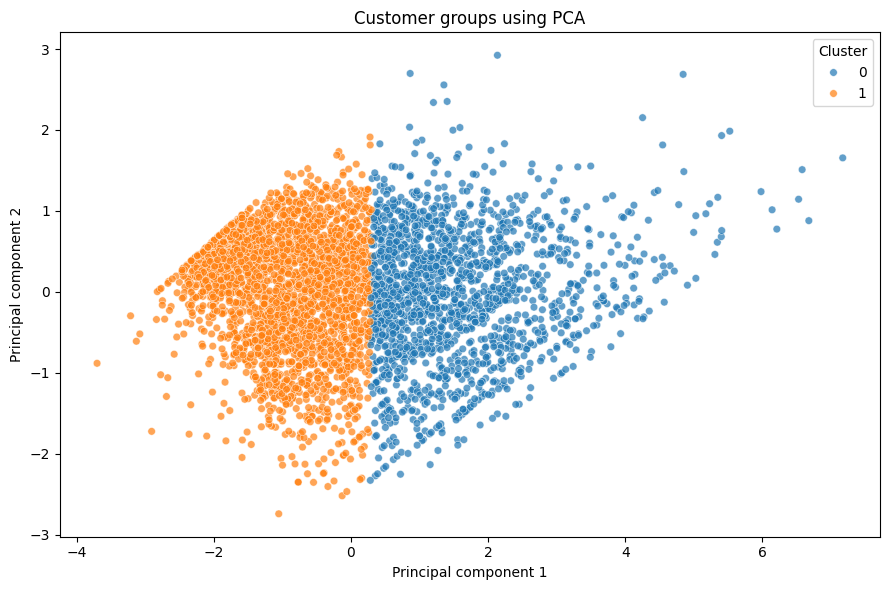

Variance shown in this plot: 93.86 %


In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": rfm["Cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", s=30, alpha=0.7)
plt.title("Customer groups using PCA")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.tight_layout()
plt.show()

print("Variance shown in this plot:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

## 13. Compare clusters

In [ ]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency_Days=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_profile["Customer_Percent"] = (
    cluster_profile["Customer_Count"] / len(rfm) * 100
).round(2)

display(cluster_profile.sort_values("Avg_Monetary", ascending=False))

,Customer_Count,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Customer_Percent
Cluster,,,,,
0,1669,26.45,8.44,4544.39,38.47
1,2669,134.72,1.67,497.12,61.53


## 14. Cluster patterns

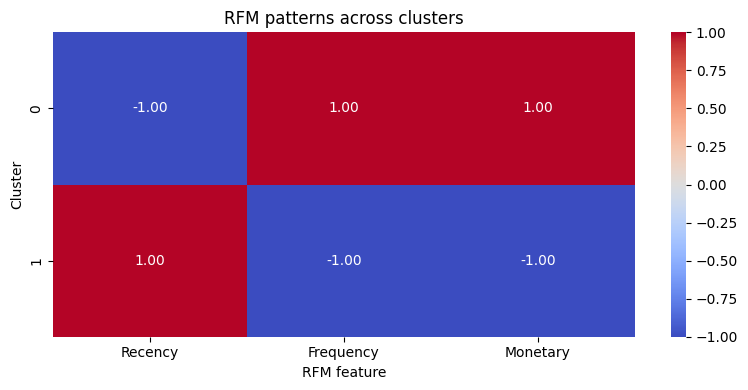

In [ ]:
profile_means = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
profile_scaled = (profile_means - profile_means.mean()) / profile_means.std(ddof=0)

plt.figure(figsize=(8, 4))
sns.heatmap(profile_scaled, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("RFM patterns across clusters")
plt.xlabel("RFM feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

## 15. Describe customer groups

In [ ]:
recency_median = rfm["Recency"].median()
frequency_median = rfm["Frequency"].median()
monetary_median = rfm["Monetary"].median()

def describe_cluster(row):
    recent = row["Avg_Recency_Days"] <= recency_median
    frequent = row["Avg_Frequency"] >= frequency_median
    high_spending = row["Avg_Monetary"] >= monetary_median

    if recent and frequent and high_spending:
        return "Recent, frequent, high-spending customers"
    if recent and frequent:
        return "Recent and frequent customers"
    if high_spending and not recent:
        return "High-spending but less-recent customers"
    if recent and not frequent:
        return "Recent, occasional customers"
    if not recent and not frequent:
        return "Less-recent, low-frequency customers"
    return "Customers with mixed buying patterns"

interpretation = cluster_profile.copy()
interpretation["Suggested_Description"] = interpretation.apply(describe_cluster, axis=1)

display(interpretation[[
    "Customer_Count", "Customer_Percent", "Avg_Recency_Days",
    "Avg_Frequency", "Avg_Monetary", "Suggested_Description"
]])

,Customer_Count,Customer_Percent,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Suggested_Description
Cluster,,,,,,
0,1669,38.47,26.45,8.44,4544.39,"Recent, frequent, high-spending customers"
1,2669,61.53,134.72,1.67,497.12,"Less-recent, low-frequency customers"


## 16. Second algorithm: Hierarchical clustering

K-Means is a **partitioning** method. To compare it with a different family of methods, this section adds **Agglomerative (hierarchical) clustering**.

How it works (bottom-up):
1. Start with every customer as its own cluster.
2. Repeatedly merge the two closest clusters.
3. Stop when the required number of clusters is left.

The result can be drawn as a **dendrogram**, which shows the full merge history. Unlike K-Means, the algorithm is deterministic (no random start), and the number of clusters can be chosen *after* looking at the dendrogram.

How "closest" is measured is the **linkage** method:
- **ward:** merge the pair that increases total within-cluster variance the least (closest to the K-Means idea)
- **complete:** distance between the two farthest points of the clusters
- **average:** average distance between all pairs of points
- **single:** distance between the two nearest points

The same scaled RFM data (`X_scaled`) is used, so the comparison with K-Means is fair.

In [ ]:
import time
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

print("Extra libraries imported.")

Extra libraries imported.


## 17. Choose linkage method

All four linkage methods are tried for K = 2 to 8. Two checks are used:
- **Silhouette score:** higher means better separated clusters
- **Cophenetic correlation:** how faithfully the dendrogram preserves the real distances between customers (closer to 1 is better)

A result is accepted only if its smallest cluster has at least `MIN_CLUSTER_PCT` % of customers. Without this rule, linkages such as *single* can score well by cutting off one or two outliers as a "cluster", which is not a useful customer segment.

Silhouette score for each linkage method:


Linkage,ward,complete,average,single
K,,,,
2,0.4086,0.5203,0.5230,0.5654
3,0.3129,0.1075,0.4668,0.4604
4,0.2746,0.1352,0.4308,0.4588
5,0.2600,0.1273,0.4129,0.4188
6,0.2581,0.1854,0.3604,0.4180
7,0.2517,0.1519,0.3514,0.3957
8,0.2173,0.1500,0.3454,0.3417


Cophenetic correlation:


Linkage,ward,complete,average,single
Cophenetic,0.5708,0.6524,0.7141,0.4902


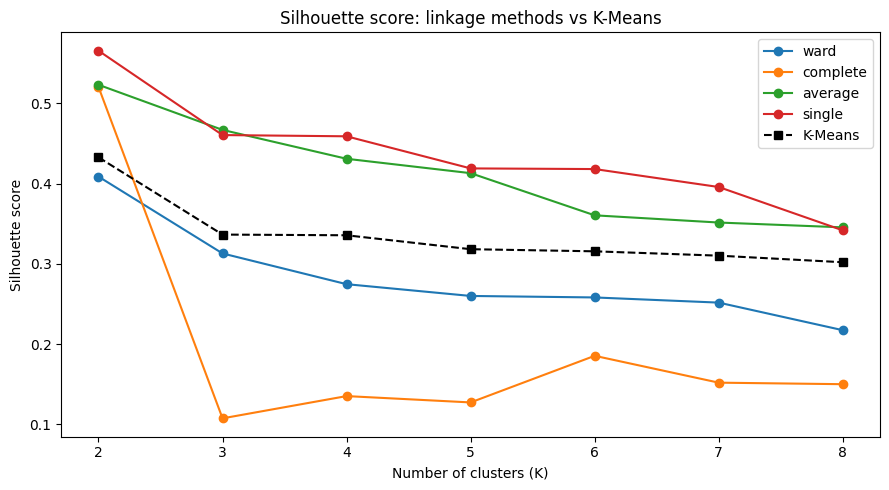

Linkage comparison at K = 2:


,Linkage,Silhouette,Smallest_Cluster_Pct,Accepted
0,ward,0.4086,42.5311,True
1,complete,0.5203,1.9594,False
2,average,0.5230,2.0516,True
3,single,0.5654,0.0231,False


Selected linkage method: average
K with the highest silhouette for this linkage: 2
For a fair comparison, both algorithms are run with K = 2 (the K chosen for K-Means).


In [ ]:
linkage_methods = ["ward", "complete", "average", "single"]
k_range = range(2, 9)
MIN_CLUSTER_PCT = 2   # a segment smaller than this % of customers is too small to act on

pairwise_dist = pdist(X_scaled)
linkage_matrices = {}
rows = []

for method in linkage_methods:
    Z_method = linkage(X_scaled, method=method)
    linkage_matrices[method] = Z_method
    coph_corr, _ = cophenet(Z_method, pairwise_dist)

    for k in k_range:
        labels = fcluster(Z_method, t=k, criterion="maxclust") - 1
        if len(np.unique(labels)) < 2:
            continue
        sizes = np.bincount(labels)
        rows.append({
            "Linkage": method,
            "K": k,
            "Silhouette": silhouette_score(X_scaled, labels),
            "Smallest_Cluster_Pct": sizes[sizes > 0].min() / len(labels) * 100,
            "Cophenetic": coph_corr,
        })

linkage_eval = pd.DataFrame(rows)

print("Silhouette score for each linkage method:")
display(linkage_eval.pivot(index="K", columns="Linkage", values="Silhouette")[linkage_methods].round(4))

print("Cophenetic correlation:")
display(linkage_eval.groupby("Linkage")["Cophenetic"].first().reindex(linkage_methods).round(4).to_frame().T)

# Plot all linkages, with K-Means (from section 10) as a reference line
plt.figure(figsize=(9, 5))
for method in linkage_methods:
    part = linkage_eval[linkage_eval["Linkage"] == method]
    plt.plot(part["K"], part["Silhouette"], marker="o", label=method)
plt.plot(evaluation["K"], evaluation["Silhouette Score"], marker="s", linestyle="--", color="black", label="K-Means")
plt.title("Silhouette score: linkage methods vs K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.legend()
plt.tight_layout()
plt.show()

# Pick the linkage with the best silhouette at the K chosen for K-Means (among practical results)
at_k = linkage_eval[linkage_eval["K"] == final_k].copy()
at_k["Accepted"] = at_k["Smallest_Cluster_Pct"] >= MIN_CLUSTER_PCT
print(f"Linkage comparison at K = {final_k}:")
display(at_k[["Linkage", "Silhouette", "Smallest_Cluster_Pct", "Accepted"]].round(4).reset_index(drop=True))

accepted = at_k[at_k["Accepted"]]
hier_linkage = accepted.loc[accepted["Silhouette"].idxmax(), "Linkage"] if not accepted.empty else "ward"
print("Selected linkage method:", hier_linkage)

# For information: the K that hierarchical clustering would pick on its own
own = linkage_eval[(linkage_eval["Linkage"] == hier_linkage) & (linkage_eval["Smallest_Cluster_Pct"] >= MIN_CLUSTER_PCT)]
hier_best_k = int(own.loc[own["Silhouette"].idxmax(), "K"]) if not own.empty else final_k
print("K with the highest silhouette for this linkage:", hier_best_k)
print(f"For a fair comparison, both algorithms are run with K = {final_k} (the K chosen for K-Means).")

## 18. Dendrogram

The dendrogram is shown in a shortened form (last 30 merges), because showing all customers would be unreadable. The height of a join is the distance at which two clusters were merged. The red dashed line is the cut that gives the chosen number of clusters.

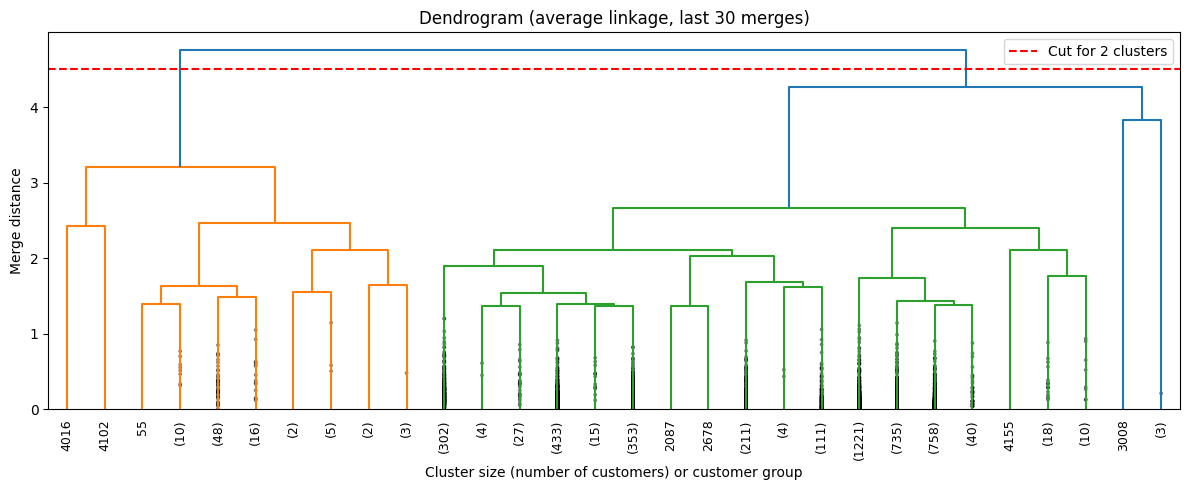

In [ ]:
Z = linkage_matrices[hier_linkage]
cut_height = (Z[-(final_k - 1), 2] + Z[-final_k, 2]) / 2

plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
)
plt.axhline(cut_height, color="red", linestyle="--", label=f"Cut for {final_k} clusters")
plt.title(f"Dendrogram ({hier_linkage} linkage, last 30 merges)")
plt.xlabel("Cluster size (number of customers) or customer group")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Apply hierarchical clustering

Cluster numbers are arbitrary (cluster 0 in one algorithm may be cluster 1 in the other). To make the results easy to compare, the hierarchical labels are renamed so that they match the K-Means labels as closely as possible. This renaming does not change the clusters or any score.

In [ ]:
def align_labels(reference, other, k):
    """Rename the cluster ids in `other` so they match `reference` as closely as possible."""
    table = pd.crosstab(reference, other).reindex(index=range(k), columns=range(k), fill_value=0).values
    row_ind, col_ind = linear_sum_assignment(-table)
    mapping = {col: row for row, col in zip(row_ind, col_ind)}
    return pd.Series(other).map(mapping).values

agglo = AgglomerativeClustering(n_clusters=final_k, linkage=hier_linkage)
hier_labels_raw = agglo.fit_predict(X_scaled)

rfm["Cluster_Hier"] = align_labels(rfm["Cluster"].values, hier_labels_raw, final_k)

hier_score = silhouette_score(X_scaled, rfm["Cluster_Hier"])

print("Linkage method:", hier_linkage)
print("Number of clusters:", final_k)
print("Silhouette score:", round(hier_score, 4))
display(rfm.head())

Linkage method: average
Number of clusters: 2
Silhouette score: 0.523


,CustomerID,Recency,Frequency,Monetary,Cluster,Cluster_Hier
0,12346,326,1,77183.60,0,1
1,12347,3,7,4310.00,0,1
2,12348,76,4,1797.24,0,1
3,12349,19,1,1757.55,1,1
4,12350,311,1,334.40,1,1


## 20. Visualize both clusterings

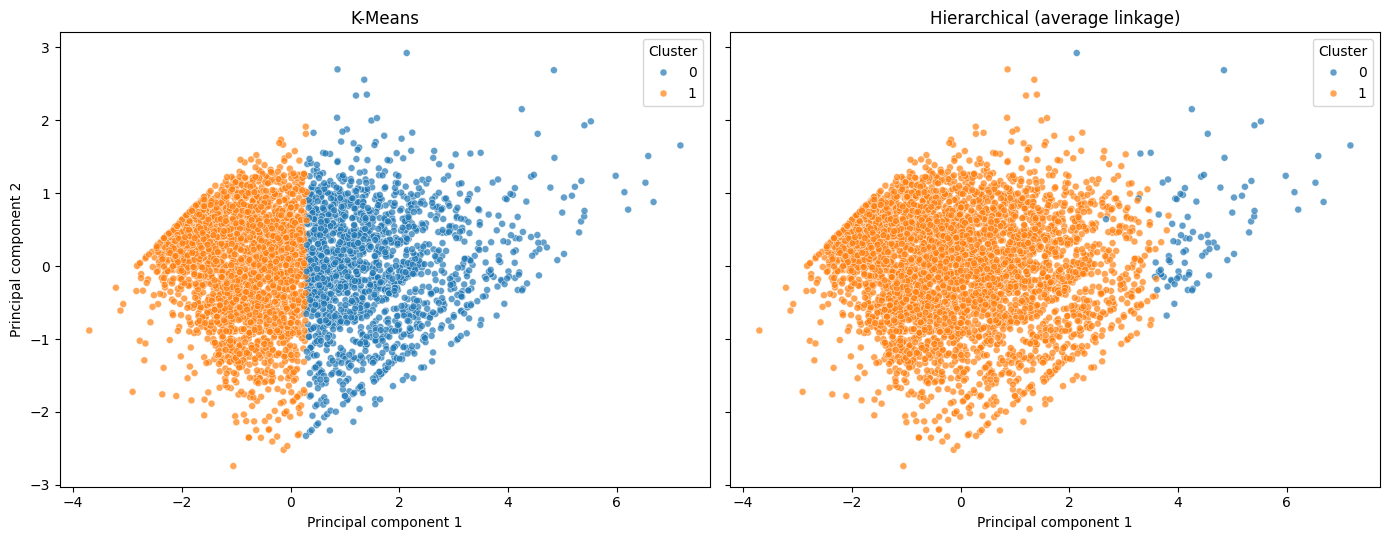

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
cluster_order = [str(i) for i in range(final_k)]

for ax, column, title in zip(
    axes,
    ["Cluster", "Cluster_Hier"],
    ["K-Means", f"Hierarchical ({hier_linkage} linkage)"],
):
    sns.scatterplot(
        x=X_pca[:, 0], y=X_pca[:, 1],
        hue=rfm[column].astype(str).values, hue_order=cluster_order,
        s=25, alpha=0.7, ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Principal component 1")
    ax.set_ylabel("Principal component 2")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()

## 21. Hierarchical cluster profile

In [ ]:
cluster_profile_hier = rfm.groupby("Cluster_Hier").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency_Days=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_profile_hier["Customer_Percent"] = (
    cluster_profile_hier["Customer_Count"] / len(rfm) * 100
).round(2)

# Same labelling rule as section 15, so the descriptions are comparable
interpretation_hier = cluster_profile_hier.copy()
interpretation_hier["Suggested_Description"] = interpretation_hier.apply(describe_cluster, axis=1)

display(interpretation_hier[[
    "Customer_Count", "Customer_Percent", "Avg_Recency_Days",
    "Avg_Frequency", "Avg_Monetary", "Suggested_Description"
]])

,Customer_Count,Customer_Percent,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Suggested_Description
Cluster_Hier,,,,,,
0,89,2.05,9.42,38.88,34120.20,"Recent, frequent, high-spending customers"
1,4249,97.95,94.81,3.55,1382.61,High-spending but less-recent customers


## 22. Comparative analysis: K-Means vs Hierarchical

Both algorithms are compared on the same data with the same number of clusters, using:
1. Internal validation metrics (no ground truth is available, so these measure cluster quality from the data itself)
2. Behaviour for different values of K
3. How much the two results agree
4. The customer groups they produce
5. A scorecard and a final verdict

### 22.1 Validation metrics

| Metric | Meaning | Better |
|---|---|---|
| Silhouette | How well each customer fits its own cluster compared to the nearest other cluster | Higher |
| Davies-Bouldin | Average similarity between each cluster and its most similar cluster | Lower |
| Calinski-Harabasz | Ratio of between-cluster spread to within-cluster spread | Higher |
| Within-cluster SSE | Total squared distance of customers from their cluster centre | Lower |
| Runtime | Time to fit the model (best of 3 runs) | Lower |

In [ ]:
def within_cluster_sse(X, labels):
    total = 0.0
    for c in np.unique(labels):
        points = X[labels == c]
        total += ((points - points.mean(axis=0)) ** 2).sum()
    return total

def best_runtime(fit_function, repeats=3):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        fit_function()
        times.append(time.perf_counter() - start)
    return min(times)

def evaluate_clustering(name, labels, runtime):
    labels = np.asarray(labels)
    sizes = np.bincount(labels)
    return {
        "Algorithm": name,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Within-cluster SSE": within_cluster_sse(X_scaled, labels),
        "Smallest cluster (%)": sizes.min() / len(labels) * 100,
        "Largest cluster (%)": sizes.max() / len(labels) * 100,
        "Runtime (s)": runtime,
    }

kmeans_runtime = best_runtime(lambda: KMeans(n_clusters=final_k, random_state=42, n_init=20).fit(X_scaled))
hier_runtime = best_runtime(lambda: AgglomerativeClustering(n_clusters=final_k, linkage=hier_linkage).fit(X_scaled))

comparison = pd.DataFrame([
    evaluate_clustering("K-Means", rfm["Cluster"].values, kmeans_runtime),
    evaluate_clustering(f"Hierarchical ({hier_linkage})", rfm["Cluster_Hier"].values, hier_runtime),
]).set_index("Algorithm")

print(f"Comparison with K = {final_k} clusters:")
display(comparison.T.round(4))

Comparison with K = 2 clusters:


Algorithm,K-Means,Hierarchical (average)
Silhouette,0.4326,0.5230
Davies-Bouldin,0.8909,0.5657
Calinski-Harabasz,4380.0168,698.1618
Within-cluster SSE,6474.1390,11209.1557
Smallest cluster (%),38.4740,2.0516
Largest cluster (%),61.5260,97.9484
Runtime (s),0.0459,0.7904


### 22.2 Effect of the number of clusters

The metrics are recalculated for K = 2 to 8, so the comparison does not depend on a single value of K.

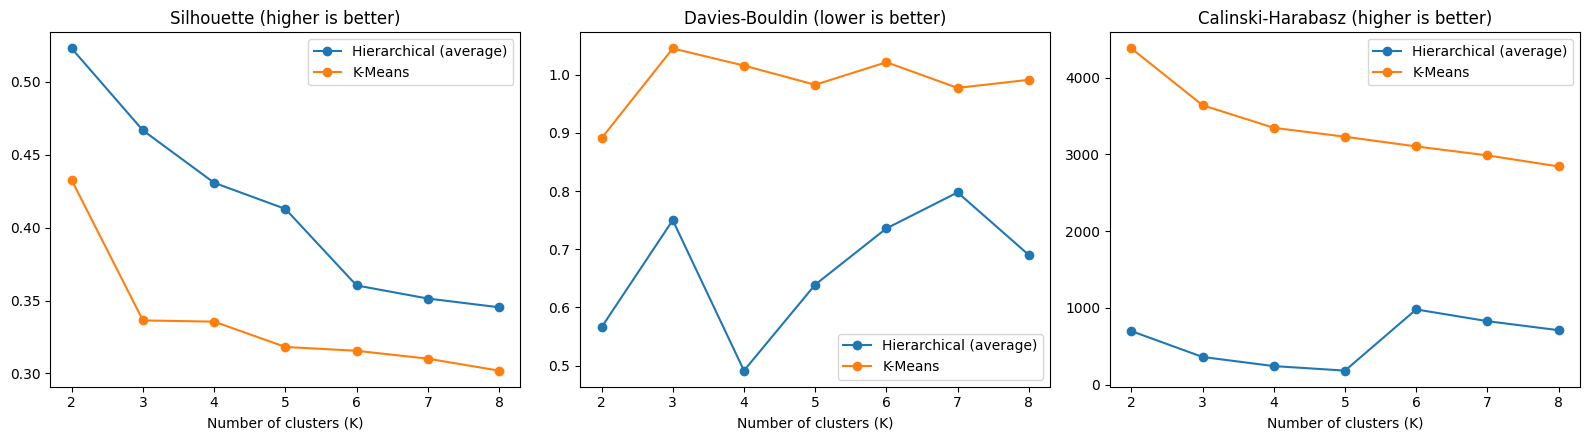

Algorithm,Hierarchical (average),K-Means
K,,
2,0.5230,0.4326
3,0.4668,0.3364
4,0.4308,0.3355
5,0.4129,0.3182
6,0.3604,0.3156
7,0.3514,0.3101
8,0.3454,0.3020


In [ ]:
hier_name = f"Hierarchical ({hier_linkage})"
sweep_rows = []

for k in k_range:
    km_labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    hc_labels = fcluster(Z, t=k, criterion="maxclust") - 1

    for name, labels in [("K-Means", km_labels), (hier_name, hc_labels)]:
        if len(np.unique(labels)) < 2:
            continue
        sweep_rows.append({
            "Algorithm": name,
            "K": k,
            "Silhouette": silhouette_score(X_scaled, labels),
            "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        })

sweep = pd.DataFrame(sweep_rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, note in zip(
    axes,
    ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
    ["higher is better", "lower is better", "higher is better"],
):
    for name, part in sweep.groupby("Algorithm"):
        ax.plot(part["K"], part[metric], marker="o", label=name)
    ax.set_title(f"{metric} ({note})")
    ax.set_xlabel("Number of clusters (K)")
    ax.legend()

plt.tight_layout()
plt.show()

display(sweep.pivot(index="K", columns="Algorithm", values="Silhouette").round(4))

### 22.3 Agreement between the two algorithms

- **Adjusted Rand Index (ARI):** 1 means identical clusterings, 0 means no better than random agreement
- **Normalized Mutual Information (NMI):** 1 means the clusterings share all their information, 0 means none
- **Same segment:** the percentage of customers placed in the same cluster by both algorithms

Adjusted Rand Index: 0.0261
Normalized Mutual Information: 0.052
Customers in the same segment: 63.58 %


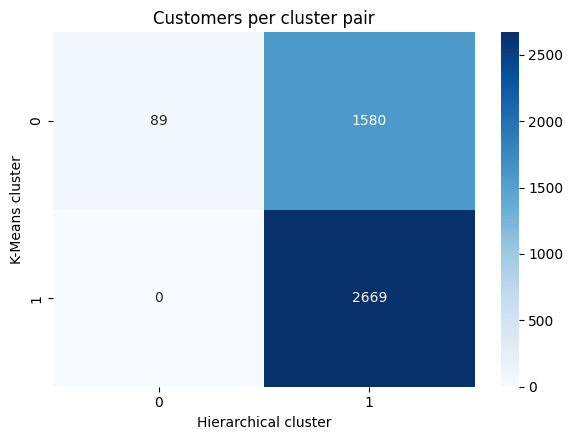

In [ ]:
ari = adjusted_rand_score(rfm["Cluster"], rfm["Cluster_Hier"])
nmi = normalized_mutual_info_score(rfm["Cluster"], rfm["Cluster_Hier"])
same_segment_pct = (rfm["Cluster"] == rfm["Cluster_Hier"]).mean() * 100

print("Adjusted Rand Index:", round(ari, 4))
print("Normalized Mutual Information:", round(nmi, 4))
print("Customers in the same segment:", round(same_segment_pct, 2), "%")

agreement = pd.crosstab(rfm["Cluster"], rfm["Cluster_Hier"], rownames=["K-Means cluster"], colnames=["Hierarchical cluster"])

plt.figure(figsize=(6, 4.5))
sns.heatmap(agreement, annot=True, fmt="d", cmap="Blues")
plt.title("Customers per cluster pair")
plt.tight_layout()
plt.show()

### 22.4 Customer groups produced by each algorithm

Average RFM values of every cluster, side by side.

,Cluster,Customer_Count,Avg_Recency_Days,Avg_Frequency,Avg_Monetary,Algorithm
0,0,1669,26.45,8.44,4544.39,K-Means
1,1,2669,134.72,1.67,497.12,K-Means
2,0,89,9.42,38.88,34120.20,Hierarchical (average)
3,1,4249,94.81,3.55,1382.61,Hierarchical (average)


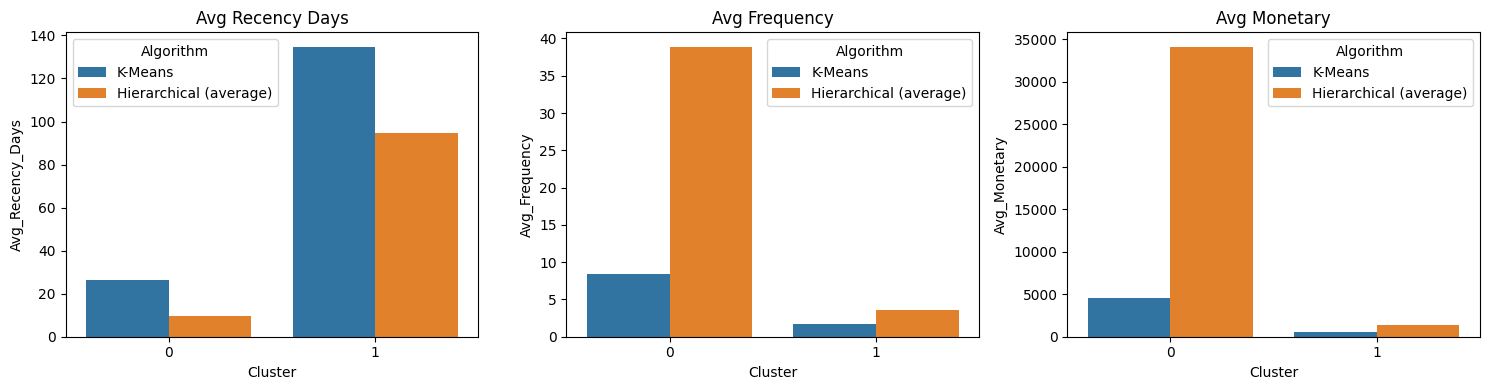

In [ ]:
def profile_table(column, name):
    table = rfm.groupby(column).agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency_Days=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
    ).rename_axis("Cluster")
    table["Algorithm"] = name
    return table.reset_index()

profile_both = pd.concat([
    profile_table("Cluster", "K-Means"),
    profile_table("Cluster_Hier", hier_name),
], ignore_index=True)

display(profile_both.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["Avg_Recency_Days", "Avg_Frequency", "Avg_Monetary"]):
    sns.barplot(data=profile_both, x="Cluster", y=feature, hue="Algorithm", ax=ax)
    ax.set_title(feature.replace("_", " "))

plt.tight_layout()
plt.show()

### 22.5 Customers who change segment

These are the customers the two algorithms disagree about. They usually sit near the boundary between two groups.

In [ ]:
disagree = rfm["Cluster"] != rfm["Cluster_Hier"]

print(f"Customers placed in different segments: {disagree.sum()} ({disagree.mean() * 100:.2f}%)")

if disagree.any():
    boundary = (
        rfm.assign(Group=np.where(disagree, "Algorithms disagree", "Algorithms agree"))
        .groupby("Group")[["Recency", "Frequency", "Monetary"]]
        .median()
        .round(2)
    )
    print("\nMedian RFM values:")
    display(boundary)

Customers placed in different segments: 1580 (36.42%)

Median RFM values:


,Recency,Frequency,Monetary
Group,,,
Algorithms agree,92.0,1.0,376.82
Algorithms disagree,18.0,5.0,1957.21


### 22.6 Scorecard and verdict

For each metric, the better algorithm is marked. Differences smaller than 0.5% are treated as a tie.

Note: K-Means directly minimises within-cluster SSE, and Silhouette and Calinski-Harabasz also favour compact, round clusters, so these metrics are naturally slightly biased towards K-Means. A close result therefore means hierarchical clustering is doing very well.

In [ ]:
metric_rules = {
    "Silhouette": "higher",
    "Davies-Bouldin": "lower",
    "Calinski-Harabasz": "higher",
    "Within-cluster SSE": "lower",
    "Runtime (s)": "lower",
}

km_row = comparison.loc["K-Means"]
hc_row = comparison.loc[hier_name]

score_rows = []
wins = {"K-Means": 0, hier_name: 0}

for metric, better in metric_rules.items():
    a, b = km_row[metric], hc_row[metric]
    if abs(a - b) <= 0.005 * max(abs(a), abs(b)):
        winner = "Tie"
    elif (a > b) == (better == "higher"):
        winner = "K-Means"
    else:
        winner = hier_name
    if winner in wins:
        wins[winner] += 1
    score_rows.append({"Metric": metric, "Better is": better, "K-Means": round(a, 4),
                       hier_name: round(b, 4), "Winner": winner})

scorecard = pd.DataFrame(score_rows)
display(scorecard)

print("Metric wins:", wins)

,Metric,Better is,K-Means,Hierarchical (average),Winner
0,Silhouette,higher,0.4326,0.5230,Hierarchical (average)
1,Davies-Bouldin,lower,0.8909,0.5657,Hierarchical (average)
2,Calinski-Harabasz,higher,4380.0168,698.1618,K-Means
3,Within-cluster SSE,lower,6474.1390,11209.1557,K-Means
4,Runtime (s),lower,0.0459,0.7904,K-Means


Metric wins: {'K-Means': 3, 'Hierarchical (average)': 2}


In [ ]:
print("FINAL VERDICT")
print("-" * 60)

if wins["K-Means"] > wins[hier_name]:
    overall = "K-Means"
elif wins[hier_name] > wins["K-Means"]:
    overall = hier_name
else:
    overall = "neither algorithm clearly (it is a tie)"

print(f"1. Quality: {overall} wins more of the validation metrics ({wins['K-Means']} vs {wins[hier_name]}).")

if ari >= 0.8:
    agreement_text = "very high agreement, so the customer segments are stable and not an artefact of one algorithm"
elif ari >= 0.5:
    agreement_text = "moderate agreement; the main segments are similar but the boundaries differ"
else:
    agreement_text = "low agreement; the two algorithms see the structure of the data differently"
print(f"2. Agreement: ARI = {ari:.3f} and {same_segment_pct:.1f}% of customers share a segment: {agreement_text}.")

faster = "K-Means" if kmeans_runtime < hier_runtime else hier_name
print(f"3. Speed: {faster} is faster on this data ({kmeans_runtime:.3f}s vs {hier_runtime:.3f}s). "
      "Hierarchical clustering needs O(n^2) memory, so it becomes slow for very large customer bases.")

print(f"4. Hierarchical clustering adds a dendrogram and needs no random start; K-Means is simpler and scales better.")

FINAL VERDICT
------------------------------------------------------------
1. Quality: K-Means wins more of the validation metrics (3 vs 2).
2. Agreement: ARI = 0.026 and 63.6% of customers share a segment: low agreement; the two algorithms see the structure of the data differently.
3. Speed: K-Means is faster on this data (0.046s vs 0.790s). Hierarchical clustering needs O(n^2) memory, so it becomes slow for very large customer bases.
4. Hierarchical clustering adds a dendrogram and needs no random start; K-Means is simpler and scales better.


### 22.7 Theoretical comparison

| Aspect | K-Means (partitioning) | Agglomerative (hierarchical) |
|---|---|---|
| Approach | Assigns points to the nearest of K centres and updates the centres repeatedly | Starts with single points and merges the closest clusters step by step |
| Need to fix K beforehand | Yes | No, the dendrogram can be cut at any level |
| Deterministic | No, depends on random start (reduced by `n_init`) | Yes, same result every run |
| Time / memory | About O(n·K·iterations), scales to large data | At least O(n²) memory and time, poor for very large data |
| Cluster shape | Compact, roughly round clusters | Depends on linkage (ward is compact, single can chain) |
| Sensitivity to outliers | High, outliers pull the centres | Depends on linkage (single and complete are sensitive) |
| Merge decisions | Can be revised in each iteration | Final, a wrong early merge cannot be undone |
| Output | Cluster labels and centroids | Labels and a full dendrogram |
| Best used when | Large data, K is known or easy to estimate | Smaller data, hierarchy or explainability is useful |

## 23. Possible uses

## 24. Save results

In [ ]:
customer_results = rfm.sort_values(["Cluster", "Monetary"], ascending=[True, False])
summary_results = interpretation.reset_index()

customer_results.to_csv("customer_segments_rfm_kmeans.csv", index=False)
summary_results.to_csv("cluster_profile_summary.csv", index=False)

print("Saved customer_segments_rfm_kmeans.csv")
print("Saved cluster_profile_summary.csv")

Saved customer_segments_rfm_kmeans.csv
Saved cluster_profile_summary.csv


In [ ]:
customer_results_both = rfm.sort_values(["Cluster", "Monetary"], ascending=[True, False])
customer_results_both.to_csv("customer_segments_rfm_comparison.csv", index=False)

interpretation_hier.reset_index().to_csv("cluster_profile_summary_hierarchical.csv", index=False)
comparison.reset_index().to_csv("algorithm_comparison_metrics.csv", index=False)
scorecard.to_csv("algorithm_comparison_scorecard.csv", index=False)

print("Saved customer_segments_rfm_comparison.csv")
print("Saved cluster_profile_summary_hierarchical.csv")
print("Saved algorithm_comparison_metrics.csv")
print("Saved algorithm_comparison_scorecard.csv")

Saved customer_segments_rfm_comparison.csv
Saved cluster_profile_summary_hierarchical.csv
Saved algorithm_comparison_metrics.csv
Saved algorithm_comparison_scorecard.csv


## Conclusion

K-Means groups customers with similar buying patterns using their RFM values.

Hierarchical (agglomerative) clustering was added as a second method and compared with K-Means on the same data and the same number of clusters. The comparison used validation metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz, SSE), runtime, the effect of K, and the agreement between the two results (ARI, NMI). The scorecard and final verdict in section 22.6 summarise which algorithm performed better on this dataset.

When two very different algorithms produce largely the same customer groups, the segmentation reflects real structure in the data rather than the choice of algorithm. In that case K-Means is the practical choice for large customer bases because it is faster and scales better, while hierarchical clustering is useful for understanding how the groups are related through the dendrogram.